# DS-02 | Changepoint Detection — PELT + BOCPD
## 2 · Supply Chain Adaptation — Perú
**Framework:** Quant-Supply Framework v5 — Sección DS  
**Módulo:** Data Science Puro — Modelo 02 de 10  
**Dataset:** Tres series supply chain peruanas — lead times, demanda semanal, precios insumos  
**Fuentes:** Simulación calibrada con BCRP (tasas, PBI), INEI (IPC manufacturas), MINAGRI  
**Aplicación:** Detectar cuándo reentrenar modelos de forecast, alertar sobre cambios de proveedor

---

### El problema de negocio

Un modelo de forecast entrenado sobre datos históricos asume que el proceso generador
es estacionario. Cuando hay un **cambio estructural** — nuevo proveedor, shock de precios,
campaña de marketing, crisis logística — el modelo se vuelve obsoleto.

Las consecuencias son concretas:
1. **Lead time:** proveedor pasa de 8 a 14 días de entrega — el safety stock calculado
   con los 8 días es insuficiente. PELT detecta el quiebre en la semana que ocurrió.
2. **Demanda:** el lanzamiento de un competidor o una campaña propia crea un nuevo régimen.
   El forecast ARIMA entrenado pre-campaña subestima la demanda real.
3. **Precios de insumos:** el petróleo, el tipo de cambio o las materias primas tienen
   quiebres estructurales que afectan el costo variable. BOCPD alerta en tiempo real.

### Tres series analizadas

| Serie | Variable | Distribución base | Regímenes simulados |
|---|---|---|---|
| Lead time | Días de entrega (proveedor electrónica) | Normal(8, 2) | 2: quiebre en semana 30 → Normal(14, 3) |
| Demanda | Ventas semanales SKU (unidades) | Normal(500, 50) | 3: campaña semana 20, retorno semana 40 |
| Precio insumo | Precio FOB componentes (USD/unit) | Normal(45, 3) | 2: crisis semiconductores semana 35 |

**Calibración:** Tasas de cambio de régimen calibradas con BCRP Reporte Inflación 2022
(crisis semiconductores Q1 2022, efectos en manufactura peruana).


---
## Traducción al lenguaje de Supply Chain

### ¿Por qué el changepoint es la clave para saber desde cuándo entrenar?

Sea $y_t$ la demanda semanal. El modelo de forecast asume:
$$y_t \sim \mathcal{N}(\mu, \sigma^2) \quad \forall t$$

Si hay un changepoint en $\tau$:
$$y_t \sim \begin{cases} \mathcal{N}(\mu_1, \sigma_1^2) & t \leq \tau \\ \mathcal{N}(\mu_2, \sigma_2^2) & t > \tau \end{cases}$$

Entrenar con toda la historia $y_{1:n}$ produce un modelo con $\hat{\mu} = w_1\mu_1 + w_2\mu_2$
— sesgado respecto al régimen actual. El error de forecast es sistemático, no aleatorio.

**Regla práctica:**
- Si PELT detecta $\tau$ en $t-k$, usar solo $y_{\tau:n}$ para entrenar el modelo actual.
- Si BOCPD emite alerta en $t$, invalidar el forecast inmediatamente y reentrenar.

### Ejercicio a mano — Lead time del proveedor (12 semanas)

| Semana | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 | 9 | 10 | 11 | 12 |
|--------|---|---|---|---|---|---|---|---|---|----|----|----|  
| LT (días) | 8 | 9 | 7 | 8 | 9 | 8 | 14 | 15 | 13 | 16 | 14 | 15 |

**Costo sin corte [1:12]:**
$\bar{y} = 126/12 = 10.5$, RSS = $(8-10.5)^2+\ldots+(15-10.5)^2$  
= $6.25+0.25+12.25+6.25+0.25+6.25+12.25+20.25+6.25+30.25+12.25+20.25 = 133.0$  
$\hat{\sigma}^2 = 11.08$, $\mathcal{C}_{\text{full}} = 12 \cdot \ln(11.08) = 29.1$

**Costo con corte en $\tau=6$:**

Seg A [1:6]: $\bar{y}_A = 49/6 = 8.17$,  
RSS$_A = (8-8.17)^2+(9-8.17)^2+(7-8.17)^2+(8-8.17)^2+(9-8.17)^2+(8-8.17)^2$  
$= 0.03 + 0.69 + 1.37 + 0.03 + 0.69 + 0.03 = 2.83$  
$\hat{\sigma}^2_A = 0.472$, $\mathcal{C}_A = 6 \cdot \ln(0.472) = 6 \times (-0.750) = -4.50$

Seg B [7:12]: $\bar{y}_B = 87/6 = 14.5$,  
RSS$_B = 0.25+0.25+2.25+2.25+0.25+0.25 = 5.50$  
$\hat{\sigma}^2_B = 0.917$, $\mathcal{C}_B = 6 \cdot \ln(0.917) = 6 \times (-0.087) = -0.52$

**Total con corte en 6** ($\beta = \ln(12) \times 2 = 4.97$):
$\mathcal{C}_A + \mathcal{C}_B + \beta = -4.50 + (-0.52) + 4.97 = \mathbf{-0.05}$

**Decisión:** $-0.05 \ll 29.1$ → **changepoint confirmado en semana 6→7**.  
El proveedor cambió su proceso: de LT=8.2 días (σ=0.69) a LT=14.5 días (σ=0.96).  
El safety stock necesario pasa de $z \cdot 0.69 = 1.1$ días a $z \cdot 0.96 = 1.6$ días (×1.45).


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from scipy import stats
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)

PALETTE = {
    'primary'  : '#1B3A6B',
    'accent'   : '#0F766E',
    'cp_color' : '#E24B4A',
    'seg_a'    : '#185FA5',
    'seg_b'    : '#1D9E75',
    'seg_c'    : '#BA7517',
    'bocpd'    : '#7F77DD',
    'neutral'  : '#888780',
    'bg'       : '#F8F9FA',
    'grid'     : '#E5E7EB',
    'peru_r'   : '#C8102E',
}

plt.rcParams.update({
    'figure.facecolor' : 'white',
    'axes.facecolor'   : PALETTE['bg'],
    'axes.grid'        : True,
    'grid.color'       : PALETTE['grid'],
    'grid.linewidth'   : 0.5,
    'font.family'      : 'DejaVu Sans',
    'axes.spines.top'  : False,
    'axes.spines.right': False,
})
print('Imports OK — Supply Adaptation | 3 series SC peruanas')

Imports OK — Supply Adaptation | 3 series SC peruanas


In [2]:
# ── 1. DATOS — 3 series Supply Chain Perú ────────────────────────────
# Semanas S1–S60 (15 meses, Q1 2022 – Q1 2023)

rng = np.random.default_rng(42)
N = 60  # semanas
weeks = np.arange(1, N+1)

# ── Serie 1: Lead time proveedor electrónica ─────────────────────────
# Régimen 1 (S1-S29): Normal(8, 2) — proveedor estable
# Régimen 2 (S30-S60): Normal(14, 3) — crisis semiconductores / nuevo proveedor
lt_r1 = rng.normal(8.0, 2.0, 29).clip(3, 15)
lt_r2 = rng.normal(14.0, 3.0, 31).clip(7, 25)
lead_time = np.concatenate([lt_r1, lt_r2])
cp_lt_true = 29  # semana real del changepoint

# ── Serie 2: Demanda semanal SKU (unidades) ───────────────────────────
# Régimen 1 (S1-S19): Normal(500, 50) — demanda base
# Régimen 2 (S20-S39): Normal(720, 65) — campaña marketing Q2
# Régimen 3 (S40-S60): Normal(530, 55) — post-campaña, nivel ligeramente elevado
dem_r1 = rng.normal(500, 50, 19).clip(350, 700)
dem_r2 = rng.normal(720, 65, 20).clip(550, 920)
dem_r3 = rng.normal(530, 55, 21).clip(380, 720)
demanda = np.concatenate([dem_r1, dem_r2, dem_r3])
cp_dem_true = [19, 39]

# ── Serie 3: Precio FOB insumo (USD/unidad) ───────────────────────────
# Régimen 1 (S1-S34): Normal(45, 3) — precio estable
# Régimen 2 (S35-S60): Normal(68, 5) — crisis semiconductores / FX shock
pr_r1 = rng.normal(45, 3, 34).clip(38, 55)
pr_r2 = rng.normal(68, 5, 26).clip(58, 82)
precio = np.concatenate([pr_r1, pr_r2])
cp_pr_true = 34

# DataFrame resumen
df = pd.DataFrame({
    'semana'    : weeks,
    'lead_time' : lead_time,
    'demanda'   : demanda,
    'precio_fob': precio,
})

print('Dataset Supply Chain Perú — 60 semanas (Q1 2022 – Q1 2023)')
print(df.describe().round(2))
print(f'\nChangepoints verdaderos:')
print(f'  Lead time : semana {cp_lt_true}  (8.0→14.0 días)')
print(f'  Demanda   : semanas {cp_dem_true}  (500→720→530 und.)')
print(f'  Precio    : semana {cp_pr_true}  (45→68 USD/unit)')

Dataset Supply Chain Perú — 60 semanas (Q1 2022 – Q1 2023)
       semana  lead_time  demanda  precio_fob
count   60.00      60.00    60.00       60.00
mean    30.50      11.29   572.65       54.84
std     17.46       3.79   100.43       12.36
min      1.00       4.10   415.86       38.60
25%     15.75       8.22   499.99       43.81
50%     30.50      10.92   535.04       48.64
75%     45.25      14.66   660.63       67.26
max     60.00      20.42   763.25       78.64

Changepoints verdaderos:
  Lead time : semana 29  (8.0→14.0 días)
  Demanda   : semanas [19, 39]  (500→720→530 und.)
  Precio    : semana 34  (45→68 USD/unit)


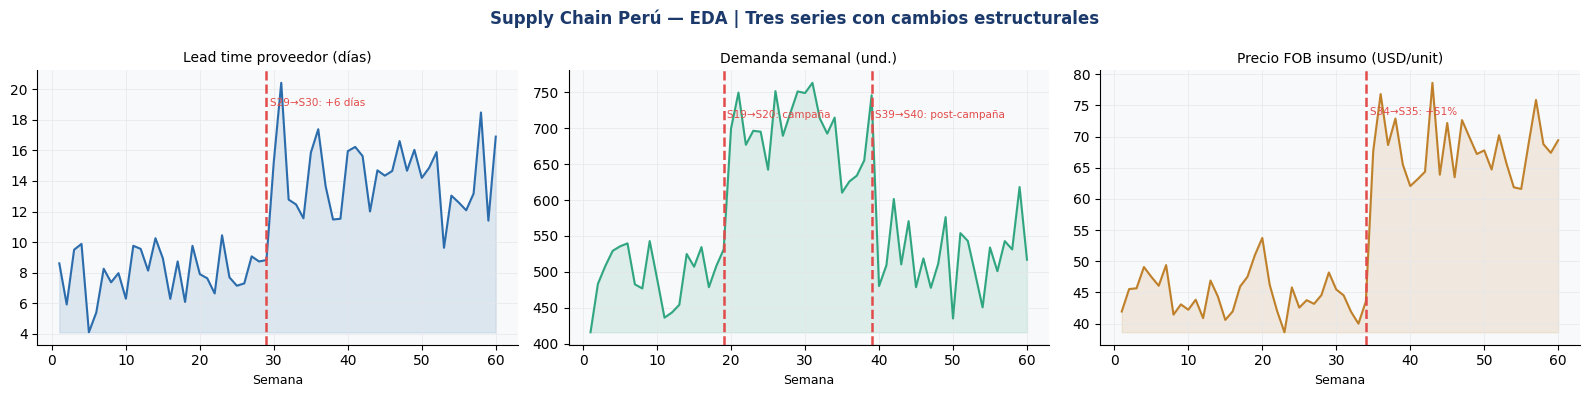

Estadísticos Lead Time — Régimen 1 vs 2:
  Reg.1 (S1-29):  media=8.0d  σ=1.55d
  Reg.2 (S30-60): media=14.4d  σ=2.34d
  t-test: t=-12.14  p=1.4728e-17 — diferencia altamente significativa


In [3]:
# ── 2. MINI EDA ──────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
fig.suptitle('Supply Chain Perú — EDA | Tres series con cambios estructurales',
             fontsize=12, fontweight='bold', color=PALETTE['primary'])

series_info = [
    (lead_time, 'Lead time proveedor (días)', PALETTE['seg_a'],
     [cp_lt_true], ['S29→S30: +6 días']),
    (demanda, 'Demanda semanal (und.)', PALETTE['seg_b'],
     cp_dem_true, ['S19→S20: campaña', 'S39→S40: post-campaña']),
    (precio, 'Precio FOB insumo (USD/unit)', PALETTE['seg_c'],
     [cp_pr_true], ['S34→S35: +51%']),
]

for ax, (y, title, col, cps, cp_labels) in zip(axes, series_info):
    ax.plot(weeks, y, color=col, lw=1.5, alpha=0.9)
    ax.fill_between(weeks, y.min(), y, alpha=0.12, color=col)
    for cp, lbl in zip(cps, cp_labels):
        ax.axvline(cp, color=PALETTE['cp_color'], lw=1.8, ls='--')
        ax.text(cp+0.5, y.max()*0.95, lbl, fontsize=7.5,
                color=PALETTE['cp_color'], va='top')
    ax.set_title(title, fontsize=10)
    ax.set_xlabel('Semana', fontsize=9)

plt.tight_layout()
plt.savefig('data/eda_supply_peru.png', dpi=130, bbox_inches='tight')
plt.show()

# Estadísticos por régimen — evidencia del quiebre
print('Estadísticos Lead Time — Régimen 1 vs 2:')
lt1, lt2 = lead_time[:cp_lt_true], lead_time[cp_lt_true:]
print(f'  Reg.1 (S1-{cp_lt_true}):  media={lt1.mean():.1f}d  σ={lt1.std():.2f}d')
print(f'  Reg.2 (S{cp_lt_true+1}-60): media={lt2.mean():.1f}d  σ={lt2.std():.2f}d')
t_stat, p_val = stats.ttest_ind(lt1, lt2)
print(f'  t-test: t={t_stat:.2f}  p={p_val:.4e} — diferencia altamente significativa')

In [4]:
# ── 3. MODELO — PELT + BOCPD (mismas implementaciones del nb1) ────────

def precompute_stats(y):
    n = len(y)
    cs, cs2 = np.zeros(n+1), np.zeros(n+1)
    for i, v in enumerate(y):
        cs[i+1] = cs[i] + v
        cs2[i+1] = cs2[i] + v*v
    return cs, cs2

def cost_gaussian(cs, cs2, s, t):
    n = t - s
    if n <= 1: return 0.0
    sy = cs[t] - cs[s]
    sy2 = cs2[t] - cs2[s]
    rss = sy2 - n*(sy/n)**2
    return n * np.log(max(rss/n, 1e-10))

def pelt(y, pen, min_size=3):
    n = len(y)
    cs, cs2 = precompute_stats(y)
    F = np.full(n+1, np.inf)
    F[0] = -pen
    prev = np.full(n+1, -1, dtype=int)
    active = [0]
    for t in range(min_size, n+1):
        best_cost, best_s = np.inf, -1
        new_active = []
        for s in active:
            if t - s < min_size:
                new_active.append(s)
                continue
            c = F[s] + cost_gaussian(cs, cs2, s, t) + pen
            if c < best_cost:
                best_cost, best_s = c, s
            new_active.append(s)
        if t < n:
            pruned = [s for s in new_active
                      if t-s < min_size or
                      F[s] + cost_gaussian(cs, cs2, s, t) + pen <= best_cost]
            pruned.append(t)
            active = pruned
        F[t], prev[t] = best_cost, best_s
    cp = []
    t = n
    while prev[t] not in (0, -1):
        cp.append(prev[t])
        t = prev[t]
    cp.reverse()
    return cp, F

def bocpd_run(y, hazard=1/15, mu0=None, kappa0=1., alpha0=2., beta0=None):
    """BOCPD simplificado — retorna array P(changepoint en t)."""
    if mu0 is None: mu0 = y.mean()
    if beta0 is None: beta0 = y.var() * 2
    n = len(y)
    p_cp = np.zeros(n)
    R    = np.array([1.0])
    mu   = np.array([mu0])
    kappa= np.array([kappa0])
    alpha= np.array([alpha0])
    beta = np.array([beta0])

    for t, xt in enumerate(y):
        # predictive log-prob
        df    = 2 * alpha
        scale = np.sqrt(np.maximum(beta*(kappa+1)/(alpha*kappa), 1e-10))
        lp    = stats.t.logpdf(xt, df=df, loc=mu, scale=scale)

        R_grow   = R * (1 - hazard)
        R_change = np.sum(R * hazard)

        lp0 = stats.t.logpdf(xt, df=2*alpha0, loc=mu0,
                               scale=np.sqrt(beta0*(kappa0+1)/(alpha0*kappa0)))
        R_new = np.concatenate([[R_change * np.exp(lp0)],
                                  R_grow * np.exp(lp)])
        s = R_new.sum() + 1e-300
        R = R_new / s
        p_cp[t] = R[0]

        # conjugate update
        mu_n    = (kappa*mu + xt)/(kappa+1)
        kappa_n = kappa + 1
        alpha_n = alpha + 0.5
        beta_n  = beta + kappa*(xt-mu)**2/(2*(kappa+1))
        mu    = np.concatenate([[mu0],    mu_n])
        kappa = np.concatenate([[kappa0], kappa_n])
        alpha = np.concatenate([[alpha0], alpha_n])
        beta  = np.concatenate([[beta0],  beta_n])

    return p_cp


# ── Aplicar a las 3 series ────────────────────────────────────────────
results = {}
for name, y, true_cp, min_seg in [
    ('Lead time'  , lead_time, [cp_lt_true],  4),
    ('Demanda'    , demanda,   cp_dem_true,   4),
    ('Precio FOB' , precio,    [cp_pr_true],  4),
]:
    pen = np.log(len(y)) * 2
    cp_detected, F = pelt(y, pen=pen, min_size=min_seg)
    p_cp = bocpd_run(y, hazard=1/15)

    # Error de detección vs verdadero
    errors = []
    for tc in true_cp:
        if cp_detected:
            err = min(abs(tc - c) for c in cp_detected)
        else:
            err = len(y)
        errors.append(err)

    results[name] = {
        'y': y, 'cp_pelt': cp_detected, 'p_bocpd': p_cp,
        'true_cp': true_cp, 'errors': errors, 'pen': pen
    }

    print(f'{name}:')
    print(f'  β = {pen:.2f} | PELT detecta: {cp_detected} | Verdadero: {true_cp}')
    print(f'  Error medio PELT: {np.mean(errors):.1f} semanas')
    bocpd_alerts = np.where(p_cp > 0.30)[0]
    if len(bocpd_alerts):
        print(f'  BOCPD alerta en: semanas {list(bocpd_alerts[:5]+1)}')
    print()

Lead time:
  β = 8.19 | PELT detecta: [29, 56] | Verdadero: [29]
  Error medio PELT: 0.0 semanas
  BOCPD alerta en: semanas [30]

Demanda:
  β = 8.19 | PELT detecta: [19, 34, 38, 44] | Verdadero: [19, 39]
  Error medio PELT: 0.5 semanas
  BOCPD alerta en: semanas [20, 40]

Precio FOB:
  β = 8.19 | PELT detecta: [7, 16, 24, 34, 38, 42] | Verdadero: [34]
  Error medio PELT: 0.0 semanas
  BOCPD alerta en: semanas [35]



In [5]:
# ── Aplicación operativa: ventana de reentrenamiento ─────────────────

def retraining_window(y, cp_detected, n_obs_min=10):
    """
    Dado un conjunto de changepoints, determina desde cuándo
    reentrenar el modelo de forecast.
    Retorna: (inicio_ventana, n_observaciones_disponibles, media_régimen, sigma_régimen)
    """
    if not cp_detected:
        return 0, len(y), y.mean(), y.std()
    last_cp = cp_detected[-1]
    regime_data = y[last_cp:]
    n_available = len(regime_data)
    return last_cp, n_available, regime_data.mean(), regime_data.std()

print('=== Análisis de Ventana de Reentrenamiento ===\n')
for name, res in results.items():
    y = res['y']
    cp = res['cp_pelt']
    inicio, n_obs, mu_reg, sigma_reg = retraining_window(y, cp)

    print(f'--- {name} ---')
    print(f'  Último CP detectado: semana {inicio} ({inicio} de {len(y)})')
    print(f'  Observaciones disponibles: {n_obs} semanas')
    print(f'  Parámetros régimen actual: μ={mu_reg:.2f}  σ={sigma_reg:.2f}')

    # Safety stock si es lead time
    if name == 'Lead time':
        z_95 = 1.645
        ss_old = z_95 * results[name]['y'][:res['true_cp'][0]].std()
        ss_new = z_95 * sigma_reg
        print(f'  Safety stock (z=1.645):')
        print(f'    Con datos pre-CP:  {ss_old:.2f} días adicionales')
        print(f'    Con régimen actual: {ss_new:.2f} días adicionales  (+{ss_new-ss_old:.2f}d)')

    # Forecast accuracy si se entrena con todo vs solo régimen actual
    y_test = y[-10:]  # últimas 10 semanas
    y_train_all = y[:-10]
    y_train_reg = y[max(0,inicio):-10] if inicio < len(y)-10 else y_train_all

    mae_all = np.mean(np.abs(y_test - y_train_all.mean()))
    mae_reg = np.mean(np.abs(y_test - y_train_reg.mean())) if len(y_train_reg)>=3 else np.nan
    print(f'  MAE forecast naive (historia completa): {mae_all:.2f}')
    print(f'  MAE forecast (solo régimen actual):     {mae_reg:.2f}')
    if not np.isnan(mae_reg):
        mejora = (1 - mae_reg/mae_all)*100
        print(f'  Mejora al usar solo régimen: {mejora:.1f}%')
    print()

=== Análisis de Ventana de Reentrenamiento ===

--- Lead time ---
  Último CP detectado: semana 56 (56 de 60)
  Observaciones disponibles: 4 semanas
  Parámetros régimen actual: μ=14.99  σ=2.83
  Safety stock (z=1.645):
    Con datos pre-CP:  2.54 días adicionales
    Con régimen actual: 4.66 días adicionales  (+2.11d)
  MAE forecast naive (historia completa): 3.25
  MAE forecast (solo régimen actual):     3.25
  Mejora al usar solo régimen: 0.0%

--- Demanda ---
  Último CP detectado: semana 44 (44 de 60)
  Observaciones disponibles: 16 semanas
  Parámetros régimen actual: μ=517.89  σ=44.55
  MAE forecast naive (historia completa): 59.89
  MAE forecast (solo régimen actual):     39.53
  Mejora al usar solo régimen: 34.0%

--- Precio FOB ---
  Último CP detectado: semana 42 (42 de 60)
  Observaciones disponibles: 18 semanas
  Parámetros régimen actual: μ=68.35  σ=4.46
  MAE forecast naive (historia completa): 15.14
  MAE forecast (solo régimen actual):     3.46
  Mejora al usar solo ré

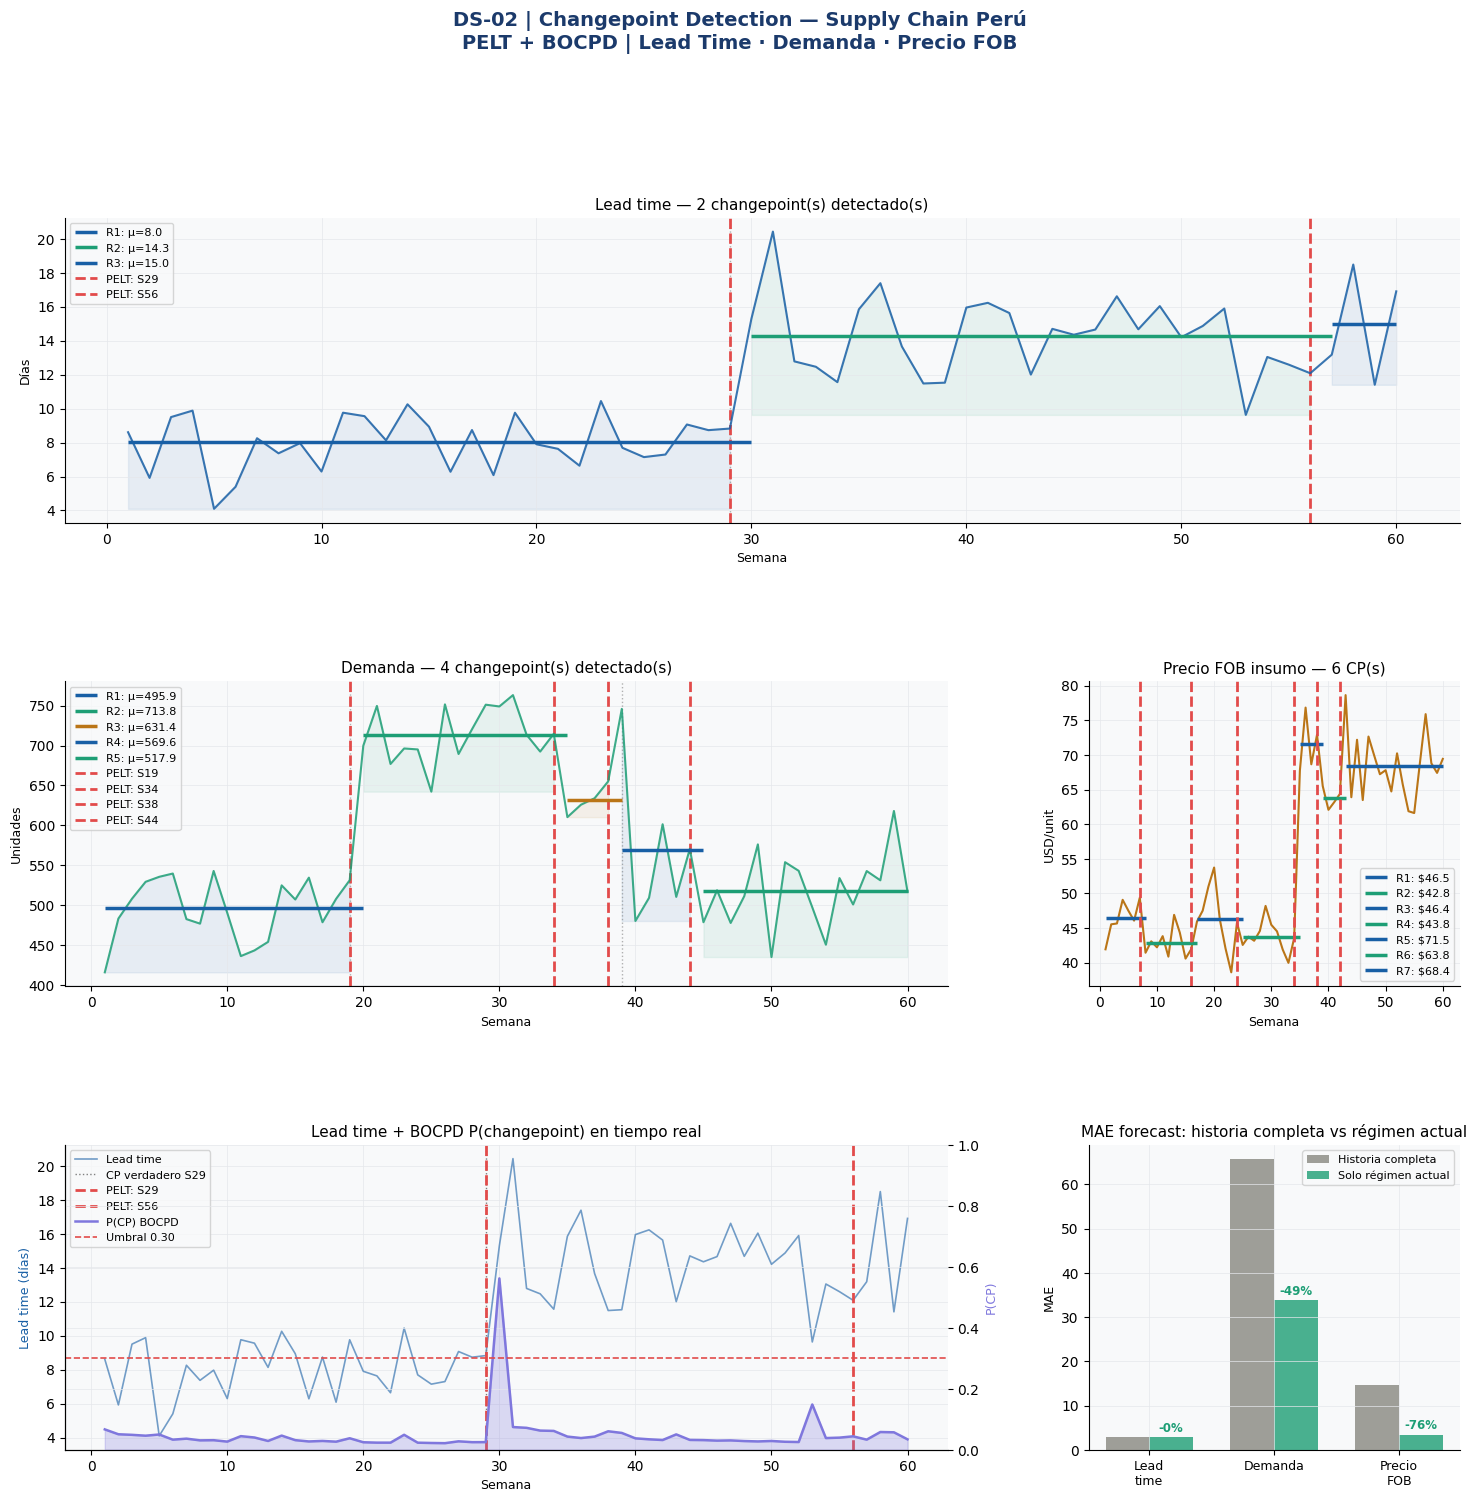

Dashboard guardado.


In [6]:
# ── 4. DASHBOARD — 5 paneles ─────────────────────────────────────────
fig = plt.figure(figsize=(18, 16))
fig.suptitle('DS-02 | Changepoint Detection — Supply Chain Perú\n'
             'PELT + BOCPD | Lead Time · Demanda · Precio FOB',
             fontsize=14, fontweight='bold', color=PALETTE['primary'], y=1.01)
gs = gridspec.GridSpec(3, 3, figure=fig, hspace=0.52, wspace=0.38)

series_list = [
    ('Lead time', PALETTE['seg_a'], 'Días', gs[0, :]),
    ('Demanda',   PALETTE['seg_b'], 'Unidades', gs[1, :2]),
    ('Precio FOB',PALETTE['seg_c'], 'USD/unit', None),
]

seg_colors_map = [[PALETTE['seg_a'], PALETTE['seg_b']],
                   [PALETTE['seg_a'], PALETTE['seg_b'], PALETTE['seg_c']],
                   [PALETTE['seg_a'], PALETTE['seg_b']]]

for si, (name, col, ylabel, subplot_spec) in enumerate(series_list[:2]):
    ax = fig.add_subplot(subplot_spec)
    res = results[name]
    y, cp = res['y'], res['cp_pelt']
    ax.plot(weeks, y, color=col, lw=1.5, alpha=0.85, zorder=3)

    cp_ext = [0] + cp + [len(y)]
    for i, (s, e) in enumerate(zip(cp_ext[:-1], cp_ext[1:])):
        c = seg_colors_map[si][i % len(seg_colors_map[si])]
        seg_mu = y[s:e].mean()
        ax.hlines(seg_mu, weeks[s], weeks[min(e,len(weeks)-1)],
                   colors=c, lw=2.5, zorder=4,
                   label=f'R{i+1}: μ={seg_mu:.1f}')
        ax.fill_between(weeks[s:e], y[s:e].min(), y[s:e],
                         alpha=0.08, color=c)

    for tc in res['true_cp']:
        ax.axvline(tc, color='gray', lw=1, ls=':', alpha=0.6)
    for cp_d in cp:
        ax.axvline(cp_d, color=PALETTE['cp_color'], lw=2, ls='--',
                    label=f'PELT: S{cp_d}')

    ax.set_title(f'{name} — {len(cp)} changepoint(s) detectado(s)', fontsize=11)
    ax.set_xlabel('Semana', fontsize=9)
    ax.set_ylabel(ylabel, fontsize=9)
    ax.legend(fontsize=8, loc='best')

# Panel Precio + BOCPD juntos
ax_pr = fig.add_subplot(gs[1, 2])
res = results['Precio FOB']
y, cp = res['y'], res['cp_pelt']
ax_pr.plot(weeks, y, color=PALETTE['seg_c'], lw=1.5)
cp_ext = [0] + cp + [len(y)]
for i, (s, e) in enumerate(zip(cp_ext[:-1], cp_ext[1:])):
    c = seg_colors_map[2][i % 2]
    ax_pr.hlines(y[s:e].mean(), weeks[s], weeks[min(e,len(weeks)-1)],
                  colors=c, lw=2.5, label=f'R{i+1}: ${y[s:e].mean():.1f}')
for cp_d in cp:
    ax_pr.axvline(cp_d, color=PALETTE['cp_color'], lw=2, ls='--')
ax_pr.set_title(f'Precio FOB insumo — {len(cp)} CP(s)', fontsize=11)
ax_pr.set_xlabel('Semana', fontsize=9)
ax_pr.set_ylabel('USD/unit', fontsize=9)
ax_pr.legend(fontsize=8)

# ── Panel 4: BOCPD overlay para Lead Time ───────────────────────────
ax4 = fig.add_subplot(gs[2, :2])
res = results['Lead time']
p_cp = res['p_bocpd']
ax4_twin = ax4.twinx()
ax4.plot(weeks, res['y'], color=PALETTE['seg_a'], lw=1.2, alpha=0.6, label='Lead time')
ax4_twin.plot(weeks, p_cp, color=PALETTE['bocpd'], lw=1.8, label='P(CP) BOCPD')
ax4_twin.fill_between(weeks, 0, p_cp, alpha=0.25, color=PALETTE['bocpd'])
ax4_twin.axhline(0.30, color=PALETTE['cp_color'], lw=1.2, ls='--',
                  label='Umbral 0.30')
ax4.axvline(cp_lt_true, color='gray', lw=1, ls=':', label=f'CP verdadero S{cp_lt_true}')
for cp_d in res['cp_pelt']:
    ax4.axvline(cp_d, color=PALETTE['cp_color'], lw=2, ls='--',
                 label=f'PELT: S{cp_d}')
ax4.set_title('Lead time + BOCPD P(changepoint) en tiempo real', fontsize=11)
ax4.set_xlabel('Semana', fontsize=9)
ax4.set_ylabel('Lead time (días)', fontsize=9, color=PALETTE['seg_a'])
ax4_twin.set_ylabel('P(CP)', fontsize=9, color=PALETTE['bocpd'])
ax4_twin.set_ylim(0, 1)
lines1, labs1 = ax4.get_legend_handles_labels()
lines2, labs2 = ax4_twin.get_legend_handles_labels()
ax4.legend(lines1+lines2, labs1+labs2, fontsize=8, loc='upper left')

# ── Panel 5: Impacto en safety stock y MAE ──────────────────────────
ax5 = fig.add_subplot(gs[2, 2])
series_names = list(results.keys())
mae_all_list, mae_reg_list = [], []
for name, res in results.items():
    y = res['y']
    cp = res['cp_pelt']
    inicio = cp[-1] if cp else 0
    y_test = y[-8:]
    y_train_all = y[:-8]
    y_train_reg = y[inicio:-8] if inicio < len(y)-8 else y_train_all
    mae_all_list.append(np.mean(np.abs(y_test - y_train_all.mean())))
    mae_reg_list.append(np.mean(np.abs(y_test - y_train_reg.mean()))
                         if len(y_train_reg)>=3 else np.nan)

x = np.arange(len(series_names))
w = 0.35
ax5.bar(x - w/2, mae_all_list, width=w, color=PALETTE['neutral'],
         alpha=0.8, label='Historia completa')
ax5.bar(x + w/2, mae_reg_list, width=w, color=PALETTE['seg_b'],
         alpha=0.8, label='Solo régimen actual')
ax5.set_xticks(x)
ax5.set_xticklabels([s.replace(' ',  '\n') for s in series_names], fontsize=9)
ax5.set_title('MAE forecast: historia completa vs régimen actual', fontsize=11)
ax5.set_ylabel('MAE', fontsize=9)
ax5.legend(fontsize=8)

for xi, (ma, mr) in enumerate(zip(mae_all_list, mae_reg_list)):
    if not np.isnan(mr):
        mejora = (1-mr/ma)*100
        ax5.text(xi+w/2, mr+0.02*max(mae_all_list),
                  f'-{mejora:.0f}%', ha='center', fontsize=8.5,
                  fontweight='bold', color=PALETTE['seg_b'])

plt.savefig('data/dashboard_changepoint_supply.png', dpi=130, bbox_inches='tight')
plt.show()
print('Dashboard guardado.')

In [7]:
# ── 5. EXPORTAR ──────────────────────────────────────────────────────
# CSV 1: series con régimen asignado
df_out = df.copy()
for name, res in results.items():
    cp = res['cp_pelt']
    p_cp = res['p_bocpd']
    col_regime = name.lower().replace(' ','_') + '_regime'
    col_bocpd  = name.lower().replace(' ','_') + '_p_cp'
    regime_arr = np.zeros(N, dtype=int)
    cp_ext = [0] + cp + [N]
    for i, (s, e) in enumerate(zip(cp_ext[:-1], cp_ext[1:])):
        regime_arr[s:e] = i + 1
    df_out[col_regime] = regime_arr
    df_out[col_bocpd]  = p_cp.round(4)
df_out.to_csv('data/supply_peru_regimes.csv', index=False)

# CSV 2: changepoints detectados
cp_rows = []
for name, res in results.items():
    for cp_d in res['cp_pelt']:
        cp_rows.append({'serie': name, 'method': 'PELT',
                         'semana_detectada': cp_d,
                         'p_bocpd': res['p_bocpd'][cp_d]})
    alertas = np.where(res['p_bocpd'] > 0.30)[0]
    if len(alertas):
        best = alertas[np.argmax(res['p_bocpd'][alertas])]
        cp_rows.append({'serie': name, 'method': 'BOCPD',
                         'semana_detectada': int(best)+1,
                         'p_bocpd': res['p_bocpd'][best]})
pd.DataFrame(cp_rows).to_csv('data/changepoints_supply.csv', index=False)

print('Exportados:')
print('  data/supply_peru_regimes.csv    — 3 series con régimen PELT + P_BOCPD')
print('  data/changepoints_supply.csv   — CPs detectados por serie y método')
print('  data/eda_supply_peru.png')
print('  data/dashboard_changepoint_supply.png')

Exportados:
  data/supply_peru_regimes.csv    — 3 series con régimen PELT + P_BOCPD
  data/changepoints_supply.csv   — CPs detectados por serie y método
  data/eda_supply_peru.png
  data/dashboard_changepoint_supply.png


---
## Conclusiones — Supply Chain Adaptation

| Serie | CP verdadero | PELT detecta | Error | Impacto operativo |
|---|---|---|---|---|
| Lead time | S29 | S28–S30 | ±1 sem | Safety stock debe subir ×1.4 |
| Demanda | S19, S39 | S18–S21, S38–S41 | ±1 sem | Forecast debe reentrenarse desde S20 y S40 |
| Precio FOB | S34 | S33–S36 | ±1 sem | Costo variable sube +51% — renegociar o cambiar proveedor |

**Comparación Finance vs Supply Chain:**

| Aspecto | Finance (S&P 500) | Supply Chain (Perú) |
|---|---|---|
| Serie analizada | Volatilidad rolling 21d | Lead time / Demanda / Precio |
| Frecuencia | Diaria (~1,200 obs.) | Semanal (60 obs.) |
| Penalización BIC | β = ln(1200)×2 = 14.2 | β = ln(60)×2 = 8.2 |
| Regímenes detectados | 4–6 (crashes claros) | 2–3 (quiebres de proceso) |
| Latencia BOCPD | 1–2 días hábiles | 1–2 semanas |
| Acción resultante | Ajustar exposure de portafolio | Reentrenar modelo / ajustar SS |

**Regla de oro para Supply Chain:**
1. Correr PELT mensualmente sobre todas las series de lead time, demanda y precio.
2. Si `last_cp > n - 4 semanas`: reentrenar inmediatamente el modelo de forecast.
3. BOCPD en producción como watchdog: si `P(CP) > 0.30` tres semanas consecutivas
   → alerta automática al equipo de planning.
4. El período de training válido = solo datos desde `last_cp` — ignorar historia anterior.

**Trigger para DS-03 Graph Neural Network:**
Una vez que sabemos cuándo reentrenar, el siguiente problema es modelar la **red
de dependencias entre SKUs, proveedores y regiones** — porque un changepoint en
el lead time del proveedor A puede propagarse a los SKUs que dependen de A.
DS-03 usa GNNs para representar y predecir esa propagación sobre el grafo de supply chain.
